In [1]:
!pip install -q loguru==0.7.2

In [2]:
from abc import ABC, abstractmethod

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from loguru import logger

BANDIT_REWARDS = [1, 2, 3, 4]
NUM_TRIALS = 20000
TAU = 1.0
PRIOR_MEAN = 0.0
PRIOR_PRECISION = 0.001
SEED = 42

In [3]:
class Bandit(ABC):

    @abstractmethod
    def __init__(self, p):
        pass

    @abstractmethod
    def __repr__(self):
        pass

    @abstractmethod
    def pull(self):
        pass

    @abstractmethod
    def update(self):
        pass

    @abstractmethod
    def experiment(self):
        pass

    @abstractmethod
    def report(self):
        pass

In [4]:
class Visualization():

    def plot1(self, algo):
        hist = algo.estimate_history
        t = np.arange(1, len(hist) + 1)
        for scale in ("linear", "log"):
            plt.figure(figsize=(9, 5))
            for i, m in enumerate(algo.true_means):
                plt.plot(t, hist[:, i], label=f"Arm {i} (true mean {m})")
                plt.axhline(m, color="gray", linestyle=":", linewidth=0.7)
            plt.xscale(scale)
            plt.xlabel(f"Trial ({scale} scale)")
            plt.ylabel("Estimated mean reward")
            plt.title(f"{algo.name}: learning process ({scale})")
            plt.legend()
            plt.tight_layout()
            plt.savefig(f"plot1_{algo.name}_{scale}.png", dpi=120)
            plt.show()
            plt.close()

    def plot2(self, eg, ts):
        for key, title in (("cum_rewards", "Cumulative reward"),
                           ("cum_regrets", "Cumulative regret")):
            plt.figure(figsize=(9, 5))
            plt.plot(getattr(eg, key), label="Epsilon-Greedy")
            plt.plot(getattr(ts, key), label="Thompson Sampling")
            plt.xlabel("Trial")
            plt.ylabel(title)
            plt.title(f"{title}: Epsilon-Greedy vs Thompson Sampling")
            plt.legend()
            plt.tight_layout()
            plt.savefig(f"plot2_{key}.png", dpi=120)
            plt.show()
            plt.close()

In [5]:
class BaseAlgorithm(Bandit):

    name = "Base"

    def __init__(self, p):
        self.true_means = np.asarray(p, dtype=float)
        self.k = len(self.true_means)
        self.best_mean = self.true_means.max()
        self.rng = np.random.default_rng(SEED)
        self.counts = np.zeros(self.k)
        self.estimates = np.zeros(self.k)
        self.chosen = []
        self.rewards = []
        self.estimate_history = None
        self.cum_rewards = None
        self.cum_regrets = None

    def __repr__(self):
        return f"{self.name}(true_means={self.true_means.tolist()})"

    def pull(self, arm):
        return self.rng.normal(self.true_means[arm], 1.0 / np.sqrt(TAU))

    @abstractmethod
    def choose(self, t):
        pass

    def update(self, arm, reward):
        self.counts[arm] += 1
        self.estimates[arm] += (reward - self.estimates[arm]) / self.counts[arm]

    def experiment(self):
        hist = np.zeros((NUM_TRIALS, self.k))
        for t in range(1, NUM_TRIALS + 1):
            arm = self.choose(t)
            reward = self.pull(arm)
            self.update(arm, reward)
            self.chosen.append(arm)
            self.rewards.append(reward)
            hist[t - 1] = self.estimates
        self.estimate_history = hist
        self.cum_rewards = np.cumsum(self.rewards)
        gaps = self.best_mean - self.true_means[np.asarray(self.chosen)]
        self.cum_regrets = np.cumsum(gaps)
        logger.info(f"{self.name}: experiment finished")

    def report(self):
        df = pd.DataFrame({"Bandit": self.chosen,
                           "Reward": self.rewards,
                           "Algorithm": self.name})
        logger.info(f"{self.name}: cumulative reward = {self.cum_rewards[-1]:.2f}")
        logger.info(f"{self.name}: cumulative regret = {self.cum_regrets[-1]:.2f}")
        logger.info(f"{self.name}: average reward = {np.mean(self.rewards):.4f}")
        logger.info(f"{self.name}: average regret = "
                    f"{self.cum_regrets[-1] / NUM_TRIALS:.4f}")
        logger.info(f"{self.name}: pulls per arm = {self.counts.astype(int).tolist()}")
        return df

In [6]:
class EpsilonGreedy(BaseAlgorithm):

    name = "EpsilonGreedy"

    def __init__(self, p):
        super().__init__(p)
        self.epsilon = 1.0

    def choose(self, t):
        self.epsilon = 1.0 / t
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.k))
        return int(np.argmax(self.estimates))

In [7]:
class ThompsonSampling(BaseAlgorithm):

    name = "ThompsonSampling"

    def __init__(self, p):
        super().__init__(p)
        self.post_precision = np.full(self.k, PRIOR_PRECISION)
        self.post_mean = np.full(self.k, PRIOR_MEAN)
        self.sums = np.zeros(self.k)

    def choose(self, t):
        samples = self.rng.normal(self.post_mean, 1.0 / np.sqrt(self.post_precision))
        return int(np.argmax(samples))

    def update(self, arm, reward):
        super().update(arm, reward)
        self.sums[arm] += reward
        self.post_precision[arm] = PRIOR_PRECISION + self.counts[arm] * TAU
        self.post_mean[arm] = (PRIOR_PRECISION * PRIOR_MEAN
                               + TAU * self.sums[arm]) / self.post_precision[arm]

In [9]:
def comparison():
    eg = EpsilonGreedy(BANDIT_REWARDS)
    ts = ThompsonSampling(BANDIT_REWARDS)
    eg.experiment()
    ts.experiment()

    df = pd.concat([eg.report(), ts.report()], ignore_index=True)
    df.to_csv("rewards.csv", index=False)
    logger.info("Rewards stored in rewards.csv")

    viz = Visualization()
    viz.plot1(eg)
    viz.plot1(ts)
    viz.plot2(eg, ts)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for algo in (eg, ts):
        axes[0].plot(algo.cum_rewards, label=algo.name)
        axes[1].plot(algo.cum_regrets, label=algo.name)
    axes[0].set_title("Cumulative reward")
    axes[1].set_title("Cumulative regret")
    for ax in axes:
        ax.set_xlabel("Trial")
        ax.legend()
    plt.tight_layout()
    plt.savefig("comparison.png", dpi=120)
    plt.show()
    plt.close()

    better = ts if ts.cum_regrets[-1] < eg.cum_regrets[-1] else eg
    logger.info(f"Lower cumulative regret: {better.name}")

2026-11-13 16:10:54.291 | INFO     | __main__:experiment:45 - EpsilonGreedy: experiment finished
2026-11-13 16:10:54.803 | INFO     | __main__:experiment:45 - ThompsonSampling: experiment finished
2026-11-13 16:10:54.823 | INFO     | __main__:report:51 - EpsilonGreedy: cumulative reward = 73907.23
2026-11-13 16:10:54.824 | INFO     | __main__:report:52 - EpsilonGreedy: cumulative regret = 6181.00
2026-11-13 16:10:54.826 | INFO     | __main__:report:53 - EpsilonGreedy: average reward = 3.6954
2026-11-13 16:10:54.828 | INFO     | __main__:report:54 - EpsilonGreedy: average regret = 0.3090
2026-11-13 16:10:54.830 | INFO     | __main__:report:56 - EpsilonGreedy: pulls per arm = [2, 3, 6169, 13826]
2026-11-13 16:10:54.842 | INFO     | __main__:report:51 - ThompsonSampling: cumulative reward = 79941.44
2026-11-13 16:10:54.843 | INFO     | __main__:report:52 - ThompsonSampling: cumulative regret = 33.00
2026-11-13 16:10:54.846 | INFO     | __main__:report:53 - ThompsonSampling: average reward

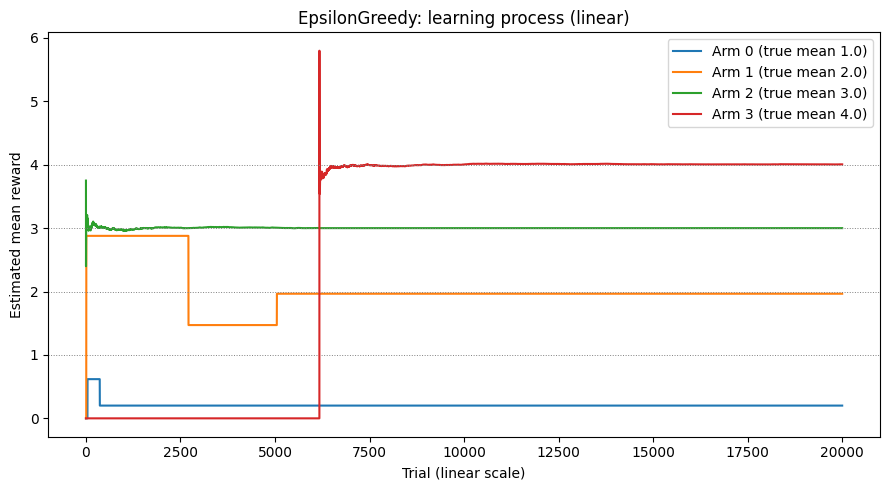

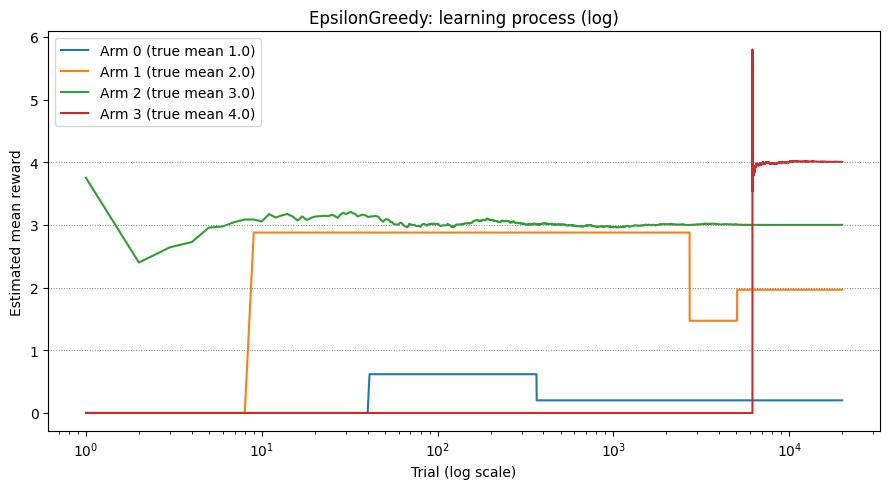

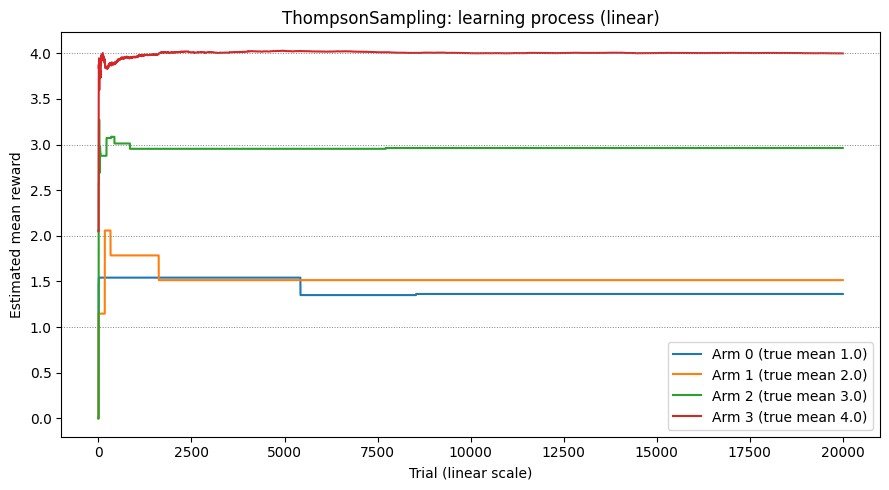

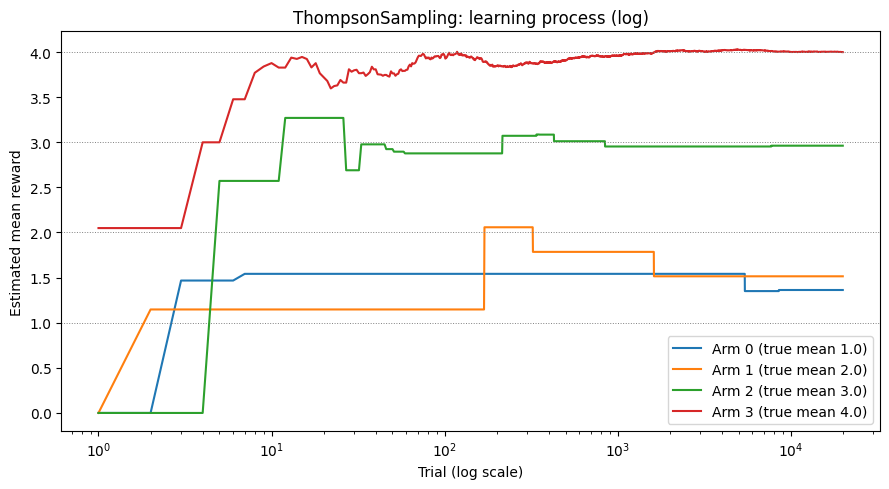

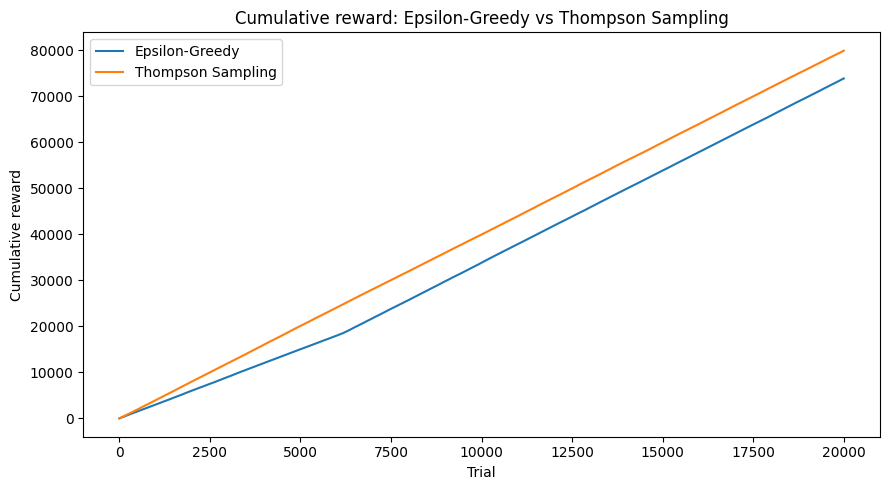

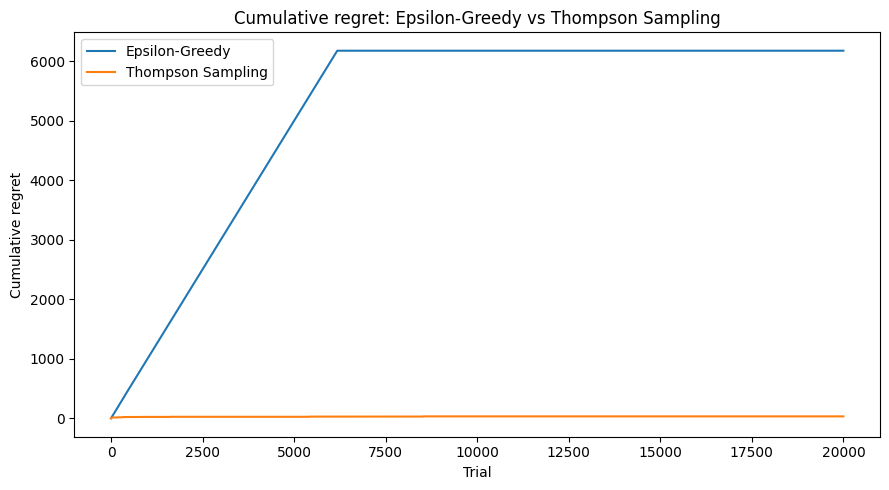

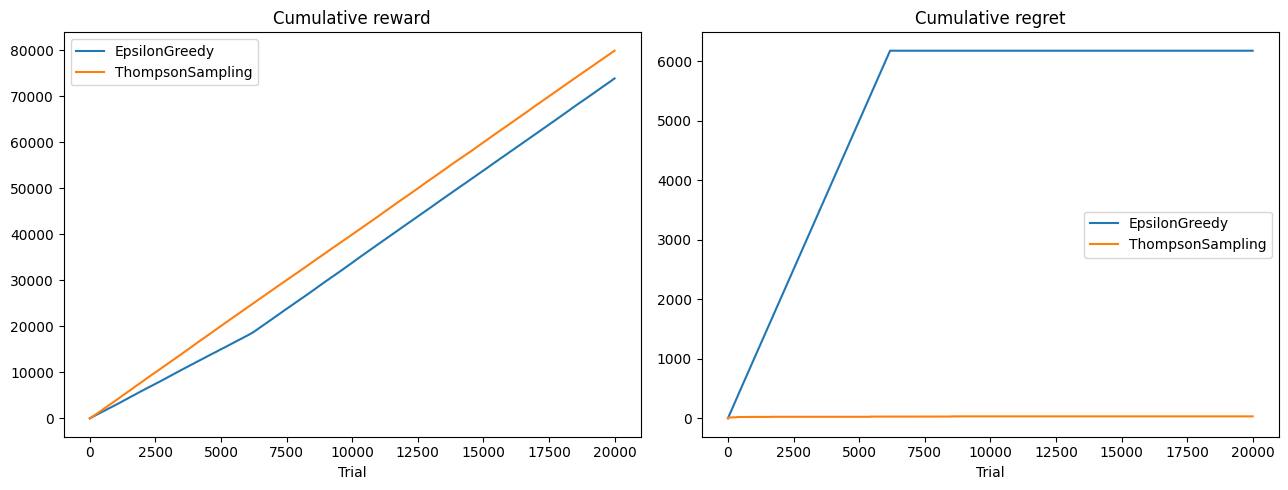

2026-11-13 16:11:01.636 | INFO     | __main__:comparison:31 - Lower cumulative regret: ThompsonSampling


In [10]:
comparison()

The 1/t decay is too aggressive for this problem. By trial 100 the exploration probability is only 1%, so the algorithm almost never tries the other ads again. If early noisy rewards make a suboptimal ad look best, it can lock onto that ad. In my run, Epsilon-Greedy spent about 6,000 of its 20,000 pulls on the second-best ad and gave the best ad only about 13,800 pulls. One improvement is a slower decay such as 1/√t, which keeps exploring for longer. A more principled option is the schedule of Auer et al., ε_t = min(1, cK / (d²t)), where K is the number of arms, d is the gap between the best and second-best arm and c is a constant. It explores more when the arms are hard to tell apart and less when they are easy to separate. A third option is UCB1, which drops random exploration altogether. It adds a bonus to each arm’s estimate that shrinks as that arm is pulled more often, so the algorithm explores in proportion to how uncertain it still is about each ad.